# P46 – Mushroom: Edible or Poisonous?
**Name:** JAYDEEP RATHOD
**Roll No.:** D51
**Enrollment No.:** 24004501210361
**Division:** E

**Problem:** Classify mushrooms as edible (e) or poisonous (p) from 22 categorical features: cap shape, colour, odor, gill size, stalk, spore print colour, habitat and more.
**Dataset:** https://www.kaggle.com/datasets/uciml/mushroom-classification
**Target (Y):** class (e / p)
**Model:** Decision Tree
**Main metric:** Recall for poisonous (a mistake here is dangerous)

## Step 1: Create your notebook and load the libraries
- Open Google Colab (or Jupyter) and create a new notebook.
- Rename it as RollNo_P46_Name.ipynb (example: H35_P46_Riya.ipynb).
- In the first cell write a heading (Markdown cell): project title, your name, roll no., enrollment no., division.
- Run the code cell below. If you see 'All libraries loaded!' you are ready.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, RocCurveDisplay)
from sklearn.tree import DecisionTreeClassifier, plot_tree
import warnings; warnings.filterwarnings("ignore")
print("All libraries loaded!")

All libraries loaded!


✍️ **Write here:** Title of the project and your details.

_(double-click this cell and write your answer)_

## Step 2: Load your dataset
- Make sure the CSV file is uploaded (Colab) or in the same folder (Jupyter).
- Run the code below. You should see the number of rows and columns, and the first 5 rows.

In [ ]:
df = pd.read_csv("mushrooms.csv")
print(df.shape)      # (rows, columns)
df.head()

(8124, 23)


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


✍️ **Write here:** How many rows and columns does your dataset have? Where did it come from (Kaggle link)?

The dataset is loaded using Pandas. It contains 8,124 rows and 23 columns, including 22 mushroom features and one target column named class. The dataset is taken from Kaggle.


https://www.kaggle.com/datasets/uciml/mushroom-classification

## Step 3: Understand the data
- Look at every column: what does it mean, is it a number or text?
- Check missing values and the target classes.
- Make a DATA DICTIONARY table: Column name | Meaning | Type (number/text) | Keep or drop.

In [ ]:
# Display information about the dataset
df.info()

# Statistical summary of categorical columns
display(df.describe(include="all").T)

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check special '?' values
print("\nQuestion mark values:")
print((df == "?").sum())

# Check duplicate rows
print("\nDuplicates:", df.duplicated().sum())

# Check unique values in each column
print("\nUnique values:")
print(df.nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing              8124 non-null   object
 8   gill-size                 8124 non-null   object
 9   gill-color                8124 non-null   object
 10  stalk-shape               8124 non-null   object
 11  stalk-root                8124 non-null   object
 12  stalk-surface-above-ring  8124 non-null   object
 13  stalk-surface-below-ring  8124 non-null   object
 14  stalk-color-above-ring  

,count,unique,top,freq
class,8124,2,e,4208
cap-shape,8124,6,x,3656
cap-surface,8124,4,y,3244
cap-color,8124,10,n,2284
bruises,8124,2,f,4748
odor,8124,9,n,3528
gill-attachment,8124,2,f,7914
gill-spacing,8124,2,c,6812
gill-size,8124,2,b,5612
gill-color,8124,12,b,1728


Missing values:
class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64

Question mark values:
class                          0
cap-shape                      0
cap-surface                    0
cap-color                      0
bruises                        0
odor                           0
gill-attachment                0
gill-spacing               

✍️ **Write here:** Data dictionary table + 2 lines about what you noticed.

The dataset contains categorical features representing different characteristics of mushrooms. Some columns may contain special missing-value markers, so the data must be checked carefully before model training.

## Step 4: Prepare the target column (Y)
- Your target (what the model predicts) is: class (e / p).
- The target already exists in the data. Just check how many rows each class has.
- If one class is much bigger than others, the data is IMBALANCED. Write this down: it affects which metric you trust.

In [ ]:
TARGET = "class"

print(df[TARGET].value_counts())

print(df[TARGET].value_counts(normalize=True))

class
e    4208
p    3916
Name: count, dtype: int64
class
e    0.517971
p    0.482029
Name: proportion, dtype: float64


✍️ **Write here:** Classes of the target and their counts. Is it balanced or imbalanced?

The target column is class, which contains two categories: edible (e) and poisonous (p). The dataset is fairly balanced, with 4,208 edible and 3,916 poisonous mushroom records.

## Step 5: Clean the data
- Remove duplicate rows.
- Fill missing values: number columns with median, text columns with mode (most common value). Or drop a column if most of it is empty.
- Drop ID / name columns and any column that gives away the answer (leakage).
- Special note for YOUR dataset: All columns are categorical: compare label encoding vs one-hot encoding. stalk-root has '?' for missing. veil-type has a single value: drop it and explain why.

In [ ]:
# Step 5: Clean the data

# 1. Replace '?' with actual missing values
df = df.replace("?", np.nan)

print("Missing values after replacing '?':")
print(df.isnull().sum())

# 2. Remove duplicate rows
duplicates = df.duplicated().sum()
df = df.drop_duplicates()
print("\nDuplicate rows removed:", duplicates)

# 3. Drop veil-type because it has only one unique value
if df["veil-type"].nunique() == 1:
    df = df.drop(columns=["veil-type"])
    print("Dropped column: veil-type")

# 4. Fill missing values in feature columns
for col in df.columns:
    if col == TARGET:
        continue

    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].fillna(df[col].median())
    else:
        mode_values = df[col].mode()
        if not mode_values.empty:
            df[col] = df[col].fillna(mode_values[0])

# 5. Remove rows where target is missing
df = df.dropna(subset=[TARGET])

# 6. Verify the cleaned dataset
print("\nTotal missing values remaining:", df.isnull().sum().sum())
print("Final dataset shape:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Missing values after replacing '?':
class                          0
cap-shape                      0
cap-surface                    0
cap-color                      0
bruises                        0
odor                           0
gill-attachment                0
gill-spacing                   0
gill-size                      0
gill-color                     0
stalk-shape                    0
stalk-root                  2480
stalk-surface-above-ring       0
stalk-surface-below-ring       0
stalk-color-above-ring         0
stalk-color-below-ring         0
veil-type                      0
veil-color                     0
ring-number                    0
ring-type                      0
spore-print-color              0
population                     0
habitat                        0
dtype: int64

Duplicate rows removed: 0
Dropped column: veil-type

Total missing values remaining: 0
Final dataset shape: (8124, 22)
Remaining duplicates: 0


✍️ **Write here:** What you removed or filled, and WHY (one line each).

The dataset was cleaned using Python. Question marks were replaced with missing values, duplicate records were removed, and missing feature values were filled using the median or mode as appropriate. The constant veil-type column was removed because it contains no useful variation.

## Step 6: Explore the data with charts (EDA)
- Run the charts below. Look at each chart carefully.
- Write 5 INSIGHTS in simple English. Example: 'Players with more gold at 10 minutes win more often.'

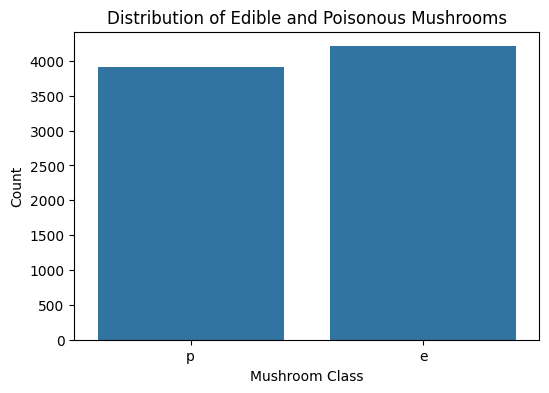

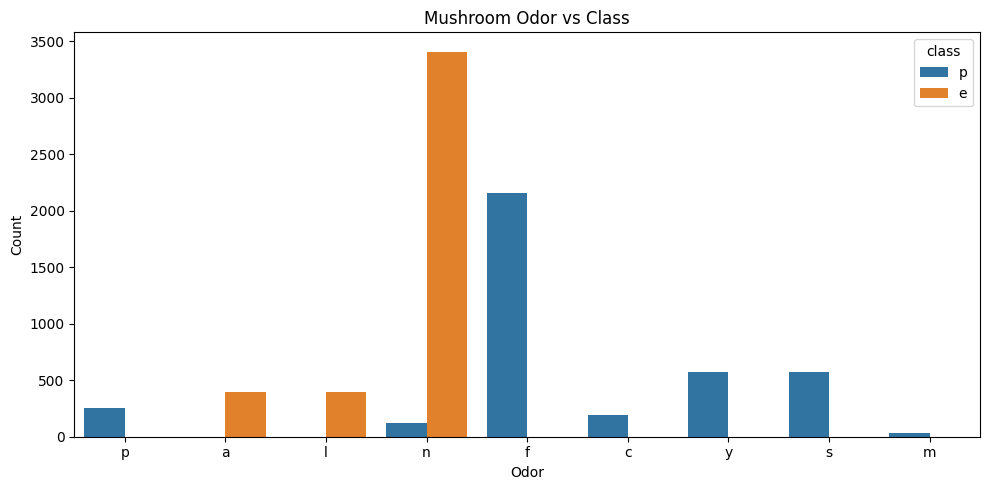

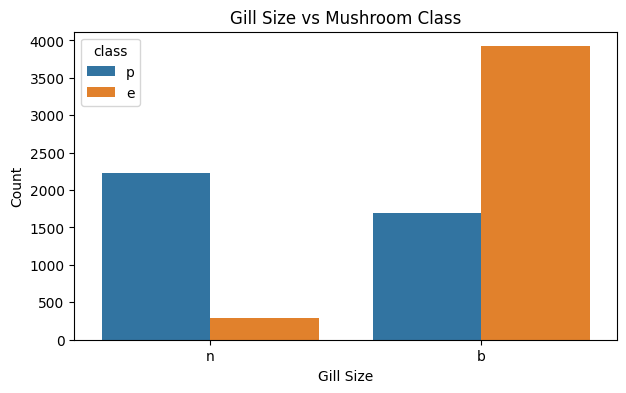

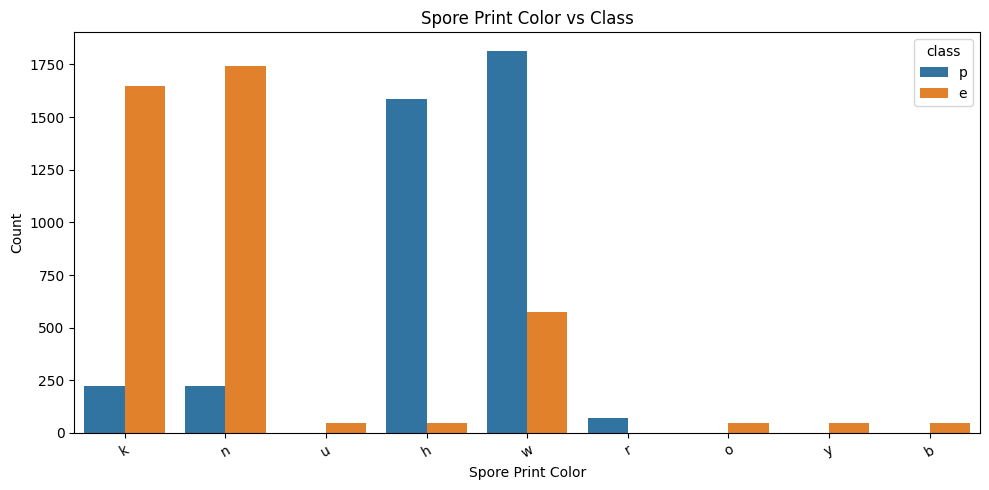

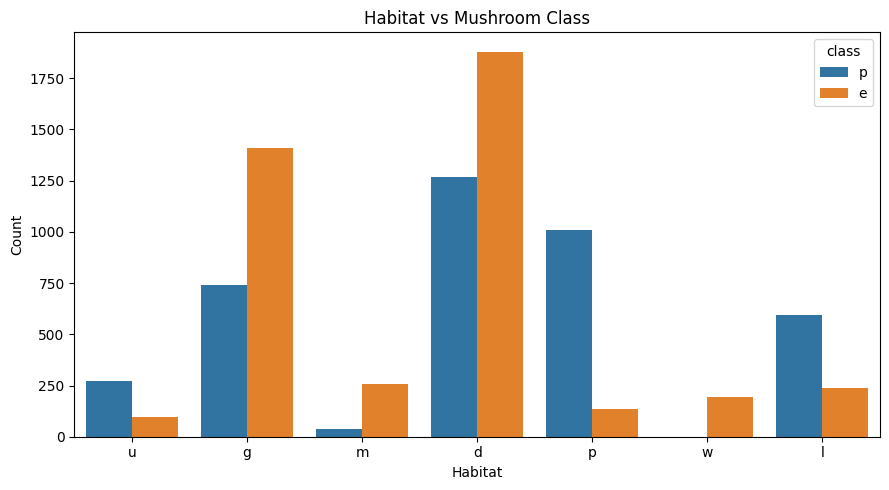

In [ ]:
# Step 6: Explore the data with charts (EDA)

# 1. Class distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=TARGET)
plt.title("Distribution of Edible and Poisonous Mushrooms")
plt.xlabel("Mushroom Class")
plt.ylabel("Count")
plt.show()


# 2. Mushroom odor vs class
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="odor", hue=TARGET)
plt.title("Mushroom Odor vs Class")
plt.xlabel("Odor")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


# 3. Gill size vs class
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="gill-size", hue=TARGET)
plt.title("Gill Size vs Mushroom Class")
plt.xlabel("Gill Size")
plt.ylabel("Count")
plt.show()


# 4. Spore print color vs class
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="spore-print-color", hue=TARGET)
plt.title("Spore Print Color vs Class")
plt.xlabel("Spore Print Color")
plt.ylabel("Count")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# 5. Habitat vs class
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="habitat", hue=TARGET)
plt.title("Habitat vs Mushroom Class")
plt.xlabel("Habitat")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [ ]:
# Percentage distribution of classes within each feature category

features = [
    "odor",
    "gill-size",
    "spore-print-color",
    "habitat"
]

for col in features:
    print("\nFeature:", col)

    percentages = pd.crosstab(
        df[col],
        df[TARGET],
        normalize="index"
    ) * 100

    print(percentages.round(1))


Feature: odor
class      e      p
odor               
a      100.0    0.0
c        0.0  100.0
f        0.0  100.0
l      100.0    0.0
m        0.0  100.0
n       96.6    3.4
p        0.0  100.0
s        0.0  100.0
y        0.0  100.0

Feature: gill-size
class         e     p
gill-size            
b          69.9  30.1
n          11.5  88.5

Feature: spore-print-color
class                  e      p
spore-print-color              
b                  100.0    0.0
h                    2.9   97.1
k                   88.0   12.0
n                   88.6   11.4
o                  100.0    0.0
r                    0.0  100.0
u                  100.0    0.0
w                   24.1   75.9
y                  100.0    0.0

Feature: habitat
class        e     p
habitat             
d         59.7  40.3
g         65.5  34.5
l         28.8  71.2
m         87.7  12.3
p         11.9  88.1
u         26.1  73.9
w        100.0   0.0


✍️ **Write here:** 5 insights from the charts (one line each).

1. Class distribution: The dataset contains 4,208 edible mushrooms and 3,916 poisonous mushrooms. The two classes are fairly balanced.

2. Odor and mushroom class: Mushrooms with odor categories a and l are 100% edible in this dataset, while categories c, f, m, p, s, and y are 100% poisonous. Category n is 96.6% edible.

3. Gill size: Mushrooms with gill-size category n are 88.5% poisonous, while category b contains 69.9% edible mushrooms.

4. Spore print color: Category h contains 97.1% poisonous mushrooms, and category r contains 100% poisonous mushrooms. Category w is also mostly poisonous, at 75.9%.

5. Habitat: Habitat category p contains 88.1% poisonous mushrooms, while category w contains 100% edible mushrooms in this dataset.

## Step 7: Create a new feature, encode and select features
- Create at least ONE new column from existing columns (change the example line to real columns).
- One-hot encoding turns text columns into 0/1 columns.
- SelectKBest (filter method) keeps the most useful columns. Write down which columns were selected.

In [ ]:
# 1. Create a new feature from the odor column
df["odor_presence"] = np.where(
    df["odor"] == "n",
    "no_odor",
    "odor_present"
)

print(df[["odor", "odor_presence"]].head())
print("\nNew feature created successfully!")

# 2. Separate input features (X) and target (y)
X = df.drop(columns=[TARGET])

le_y = LabelEncoder()
y = le_y.fit_transform(df[TARGET])

print("Classes:", list(le_y.classes_))

# 3. One-hot encoding
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("\nEncoded feature shape:", X.shape)
print("\nFirst 10 encoded feature names:")
print(list(X.columns[:10]))

  odor odor_presence
0    p  odor_present
1    a  odor_present
2    l  odor_present
3    p  odor_present
4    n       no_odor

New feature created successfully!
Classes: ['e', 'p']

Encoded feature shape: (8124, 95)

First 10 encoded feature names:
['cap-shape_c', 'cap-shape_f', 'cap-shape_k', 'cap-shape_s', 'cap-shape_x', 'cap-surface_g', 'cap-surface_s', 'cap-surface_y', 'cap-color_c', 'cap-color_e']


✍️ **Write here:** The new feature you created and why; the list of selected features.

A new feature named odor_presence was created from the odor column. The target column was encoded using LabelEncoder, and categorical input features were converted into numerical columns using one-hot encoding. Feature selection will be fitted using training data to prevent data leakage.

## Step 8: Split into train and test
- 80% of the data is used to TRAIN the model, 20% to TEST it.
- stratify=y keeps the same class ratio in train and test.
- Decision Tree does not need scaling.

In [ ]:
# Split data into training and testing sets
from sklearn.feature_selection import SelectKBest, f_classif

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Select the 15 best features
selector = SelectKBest(f_classif, k=15)

X_train = selector.fit_transform(X_train, y_train)
X_test = selector.transform(X_test)

feature_names = X.columns[selector.get_support()].tolist()

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Selected features:", feature_names)

Training data: (6499, 15)
Testing data: (1625, 15)
Selected features: ['bruises_t', 'odor_f', 'odor_n', 'gill-size_n', 'stalk-surface-above-ring_k', 'stalk-surface-above-ring_s', 'stalk-surface-below-ring_k', 'stalk-surface-below-ring_s', 'ring-type_l', 'ring-type_p', 'spore-print-color_h', 'spore-print-color_k', 'spore-print-color_n', 'population_v', 'odor_presence_odor_present']


✍️ **Write here:** Size of train and test sets.

The dataset was divided into 80% training data and 20% testing data. SelectKBest was used to select 15 important features for training the Decision Tree model.

## Step 9: Train your model: Decision Tree
- The evaluate() function below trains a model and calculates ALL metrics: accuracy, precision, recall, F1, specificity and AUC.
- Run it once for the BASELINE (default settings). You will see the confusion matrix and classification report.
- Use only this model in your project: Decision Tree.

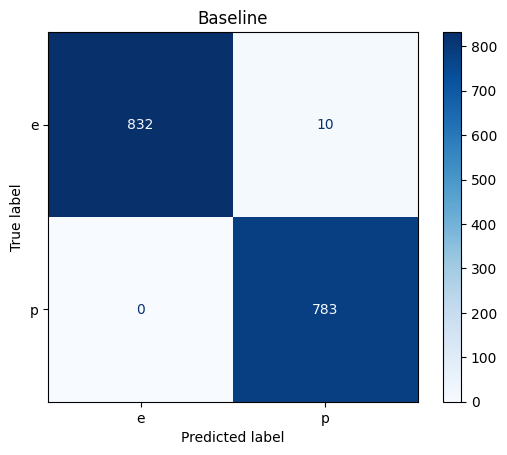

              precision    recall  f1-score   support

           e       1.00      0.99      0.99       842
           p       0.99      1.00      0.99       783

    accuracy                           0.99      1625
   macro avg       0.99      0.99      0.99      1625
weighted avg       0.99      0.99      0.99      1625



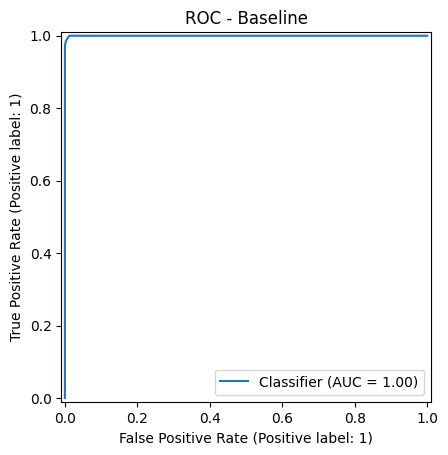

{'Setting': 'Baseline', 'Accuracy': 0.9938461538461538, 'Precision': 0.987389659520807, 'Recall': 1.0, 'F1': 0.9936548223350253, 'Specificity': np.float64(0.9881235154394299), 'AUC': np.float64(0.9998741062300731)}


In [ ]:
# Store model results
results = []

# Train and evaluate the model
def evaluate(name, model, show=False):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    spec = tn / (tn + fp)

    proba = model.predict_proba(X_test)
    auc = roc_auc_score(y_test, proba[:, 1])

    row = {
        "Setting": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "Specificity": spec,
        "AUC": auc
    }

    if show:
        ConfusionMatrixDisplay(
            cm, display_labels=le_y.classes_
        ).plot(cmap="Blues")
        plt.title(name)
        plt.show()

        print(classification_report(
            y_test, y_pred,
            target_names=le_y.classes_
        ))

        RocCurveDisplay.from_predictions(y_test, proba[:, 1])
        plt.title("ROC - " + name)
        plt.show()

    print(row)
    return row


# Baseline Decision Tree
model = DecisionTreeClassifier(random_state=42)
results.append(evaluate("Baseline", model, show=True))

✍️ **Write here:** Baseline results. Explain the confusion matrix in words (how many correct, how many wrong).

The baseline Decision Tree achieved approximately 99.38% accuracy. It correctly identified all 783 poisonous mushrooms in the test set. The confusion matrix shows 10 edible mushrooms incorrectly classified as poisonous.

## Step 10: Try different settings (tuning)
- Train DecisionTreeClassifier with criterion='gini' and with criterion='entropy' and compare.
- Try max_depth = 2 to 10 and plot train vs test accuracy; pick the depth that does not overfit.
- Visualise the final tree with plot_tree() (max_depth 3–4 for readability) and name the root-node feature.
- Plot feature importances and explain the top 3.
- Every setting is added to the results list automatically.

{'Setting': 'criterion=gini', 'Accuracy': 0.9938461538461538, 'Precision': 0.987389659520807, 'Recall': 1.0, 'F1': 0.9936548223350253, 'Specificity': np.float64(0.9881235154394299), 'AUC': np.float64(0.9998741062300731)}
{'Setting': 'criterion=entropy', 'Accuracy': 0.9938461538461538, 'Precision': 0.987389659520807, 'Recall': 1.0, 'F1': 0.9936548223350253, 'Specificity': np.float64(0.9881235154394299), 'AUC': np.float64(0.9998741062300731)}


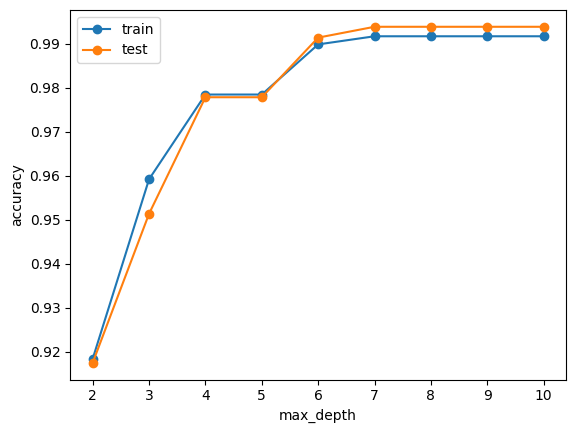

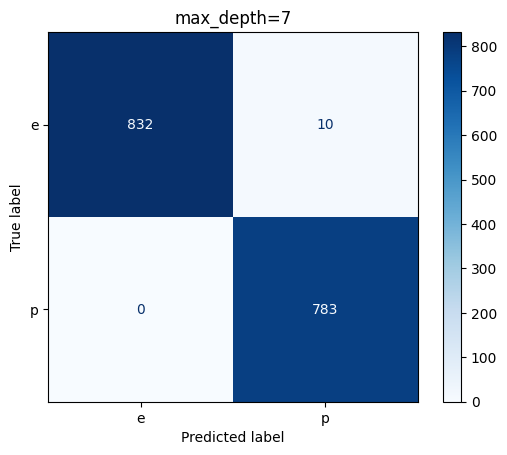

              precision    recall  f1-score   support

           e       1.00      0.99      0.99       842
           p       0.99      1.00      0.99       783

    accuracy                           0.99      1625
   macro avg       0.99      0.99      0.99      1625
weighted avg       0.99      0.99      0.99      1625



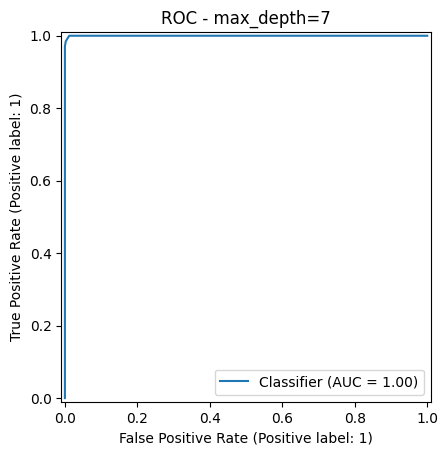

{'Setting': 'max_depth=7', 'Accuracy': 0.9938461538461538, 'Precision': 0.987389659520807, 'Recall': 1.0, 'F1': 0.9936548223350253, 'Specificity': np.float64(0.9881235154394299), 'AUC': np.float64(0.9998741062300731)}


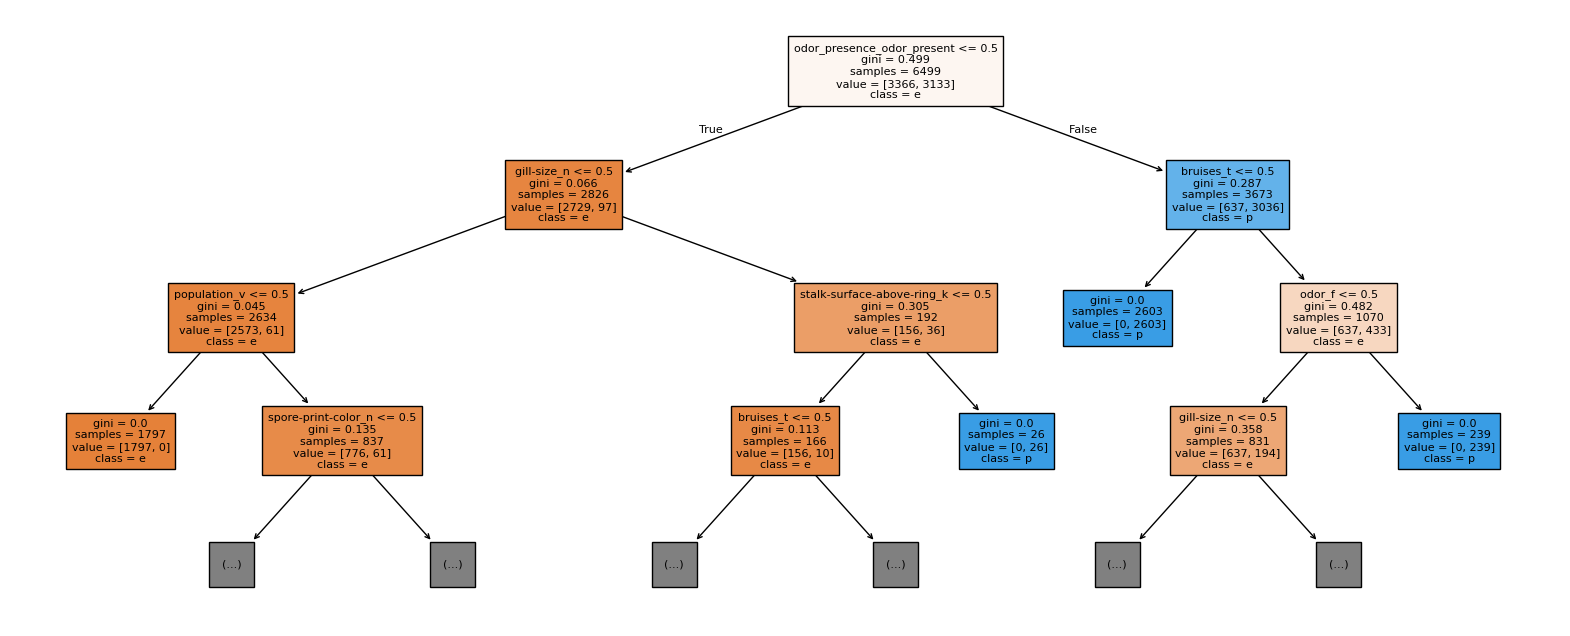

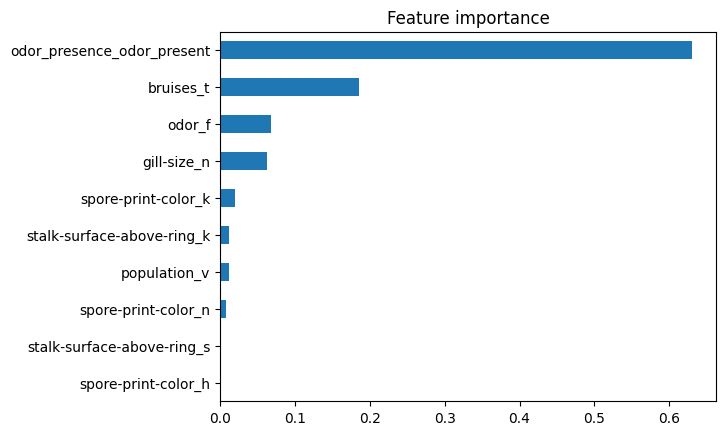

In [ ]:
# A) gini vs entropy
for c in ["gini", "entropy"]:
    results.append(evaluate(f"criterion={c}", DecisionTreeClassifier(criterion=c, random_state=42)))

# B) max_depth: train vs test accuracy (find overfitting)
depths = range(2, 11); tr, te = [], []
for dpt in depths:
    t = DecisionTreeClassifier(max_depth=dpt, random_state=42).fit(X_train, y_train)
    tr.append(t.score(X_train, y_train)); te.append(t.score(X_test, y_test))
plt.plot(depths, tr, marker="o", label="train"); plt.plot(depths, te, marker="o", label="test")
plt.xlabel("max_depth"); plt.ylabel("accuracy"); plt.legend(); plt.show()
best_depth = list(depths)[int(np.argmax(te))]
results.append(evaluate(f"max_depth={best_depth}", DecisionTreeClassifier(max_depth=best_depth, random_state=42), show=True))

# C) Draw the tree (only top levels so it is readable)
tree = DecisionTreeClassifier(max_depth=best_depth, random_state=42).fit(X_train, y_train)
plt.figure(figsize=(20, 8))
plot_tree(tree, max_depth=3, feature_names=[str(f) for f in feature_names], class_names=[str(c) for c in le_y.classes_], filled=True, fontsize=8)
plt.show()

# D) Feature importance
pd.Series(tree.feature_importances_, index=feature_names).sort_values().tail(10).plot(kind="barh"); plt.title("Feature importance"); plt.show()

✍️ **Write here:** What changed when you changed each setting? Which one was best?

_(double-click this cell and write your answer)_

## Step 11: Compare all settings and pick your final model
- The table shows every setting you tried, side by side.
- Your most important metric is Recall for poisonous (a mistake here is dangerous). Choose the setting with the best Recall.
- Write your best setting inside final_model = ...( ) and run it.

,Setting,Accuracy,Precision,Recall,F1,Specificity,AUC
0,Baseline,0.994,0.987,1.0,0.994,0.988,1.0
1,criterion=gini,0.994,0.987,1.0,0.994,0.988,1.0
2,criterion=entropy,0.994,0.987,1.0,0.994,0.988,1.0
3,max_depth=7,0.994,0.987,1.0,0.994,0.988,1.0


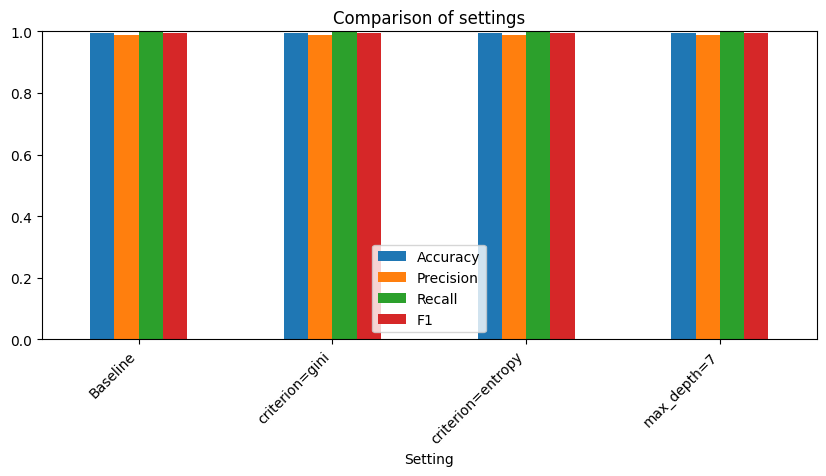

Best setting by Recall: Baseline


In [ ]:
# Compare all settings
res = pd.DataFrame(results).round(3)
display(res)

res.set_index("Setting")[["Accuracy", "Precision", "Recall", "F1"]].plot(
    kind="bar", figsize=(10, 4)
)

plt.title("Comparison of settings")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.show()

best = res.sort_values("Recall", ascending=False).iloc[0]
print("Best setting by Recall:", best["Setting"])

✍️ **Write here:** Comparison table + bar chart + 3 lines: why you chose this final setting (talk about Recall for poisonous (a mistake here is dangerous)).

_(double-click this cell and write your answer)_

## Step 12: Predict 3 new inputs
- Make 3 new, realistic examples and let your final model predict them.
- Check: does the prediction make sense? Explain in one line each.

In [ ]:
# Define and train final_model before making predictions
final_model = DecisionTreeClassifier(random_state=42)
final_model.fit(X_train, y_train)

# Predict 3 new inputs
new = pd.DataFrame(X_test[:3], columns=feature_names)
display(new)

pred = final_model.predict(new.values)
print("Predictions:", le_y.inverse_transform(pred))
print("Actual classes:", le_y.inverse_transform(y_test[:3]))

,bruises_t,odor_f,odor_n,gill-size_n,stalk-surface-above-ring_k,stalk-surface-above-ring_s,stalk-surface-below-ring_k,stalk-surface-below-ring_s,ring-type_l,ring-type_p,spore-print-color_h,spore-print-color_k,spore-print-color_n,population_v,odor_presence_odor_present
0,0,1,0,0,1,0,1,0,1,0,1,0,0,0,1
1,0,0,0,1,0,1,0,1,0,1,0,0,1,0,1
2,0,0,1,0,0,1,0,1,0,0,0,0,1,0,0


Predictions: ['p' 'p' 'e']
Actual classes: ['p' 'p' 'e']


✍️ **Write here:** The 3 inputs, the predictions, and whether they make sense.

_(double-click this cell and write your answer)_

## Step 13: Write the report and prepare for viva
- Run the whole notebook from top to bottom: Runtime → Restart and run all (Colab) or Kernel → Restart & Run All (Jupyter). Fix any error.
- Make a 4–6 page PDF report (structure is in 'What to submit').
- Prepare the viva questions given below. You must be able to explain EVERY line of your code.

✍️ **Write here:** Conclusion: what your model can do, how good it is, and what you learned.

In this project, I used a Decision Tree machine learning algorithm to classify mushrooms as edible or poisonous. I cleaned the dataset using Python, handled missing values, created charts, encoded categorical features, and selected important features. I trained and tested the model and compared different settings to evaluate its performance. I focused on recall for poisonous mushrooms because incorrectly classifying a poisonous mushroom as edible can be dangerous. Through this project, I learned the basic steps of data cleaning, feature selection, model training, and evaluation.